<a href="https://colab.research.google.com/github/hayetmece/IRIS-Decision-Tree-Random-Forest/blob/main/iris_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IRIS: Decision Tree ثم Random Forest
شغّلي الخلايا بالترتيب (Shift+Enter).

## 1) تحميل البيانات

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
X, y = iris.data, iris.target
print(df.shape)
df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [3]:
df['target'].value_counts()

,count
target,
0,50
1,50
2,50


## 2) تقسيم البيانات (تدريب / اختبار)

In [4]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print(Xtr.shape, Xte.shape)

(105, 4) (45, 4)


## 3) Decision Tree + plot_tree

Accuracy: 0.9777777777777777
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



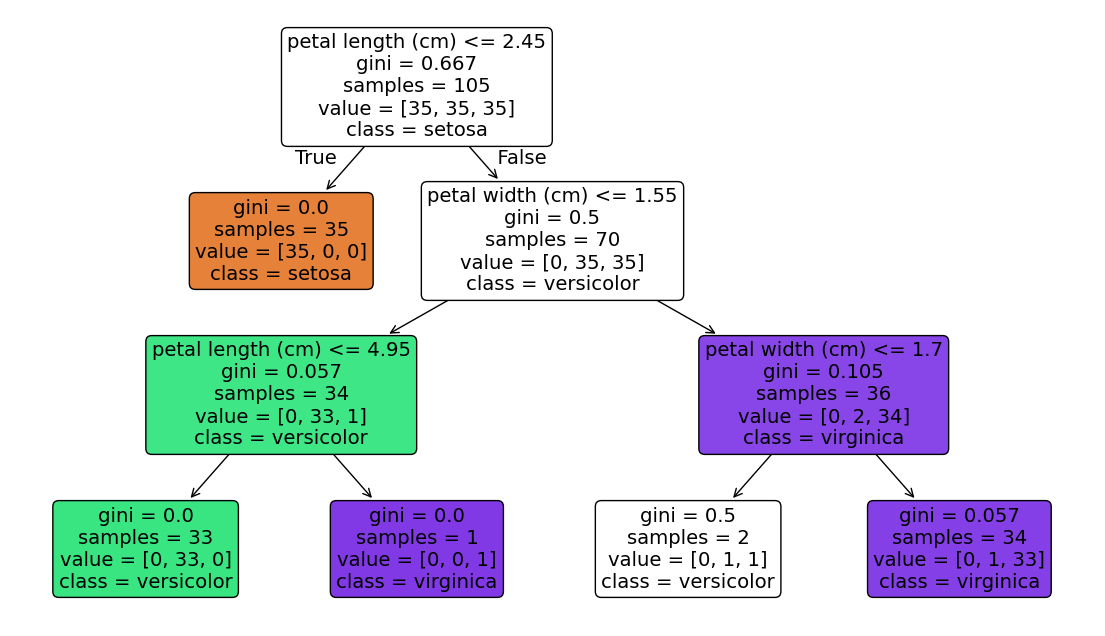

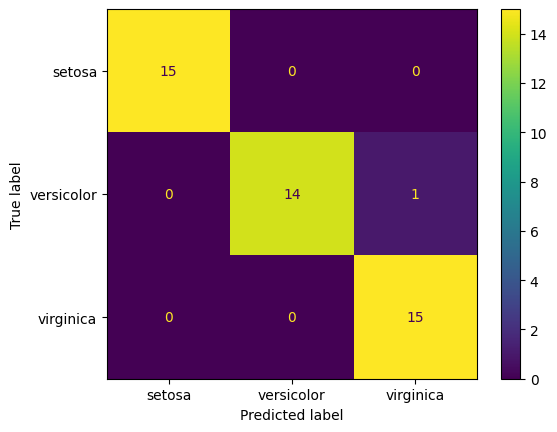

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

dt = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xtr, ytr)
pred = dt.predict(Xte)
print("Accuracy:", accuracy_score(yte, pred))
print(classification_report(yte, pred, target_names=iris.target_names))

plt.figure(figsize=(14, 8))
plot_tree(dt, feature_names=iris.feature_names,
          class_names=list(iris.target_names), filled=True, rounded=True)
plt.show()

ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=iris.target_names)
plt.show()

## 4) Random Forest

Accuracy: 0.8888888888888888
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45



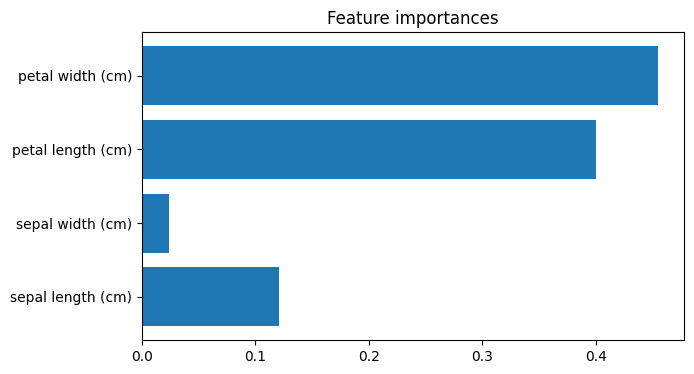

In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(Xtr, ytr)
pred_rf = rf.predict(Xte)
print("Accuracy:", accuracy_score(yte, pred_rf))
print(classification_report(yte, pred_rf, target_names=iris.target_names))

plt.figure(figsize=(7, 4))
plt.barh(iris.feature_names, rf.feature_importances_)
plt.title("Feature importances")
plt.show()

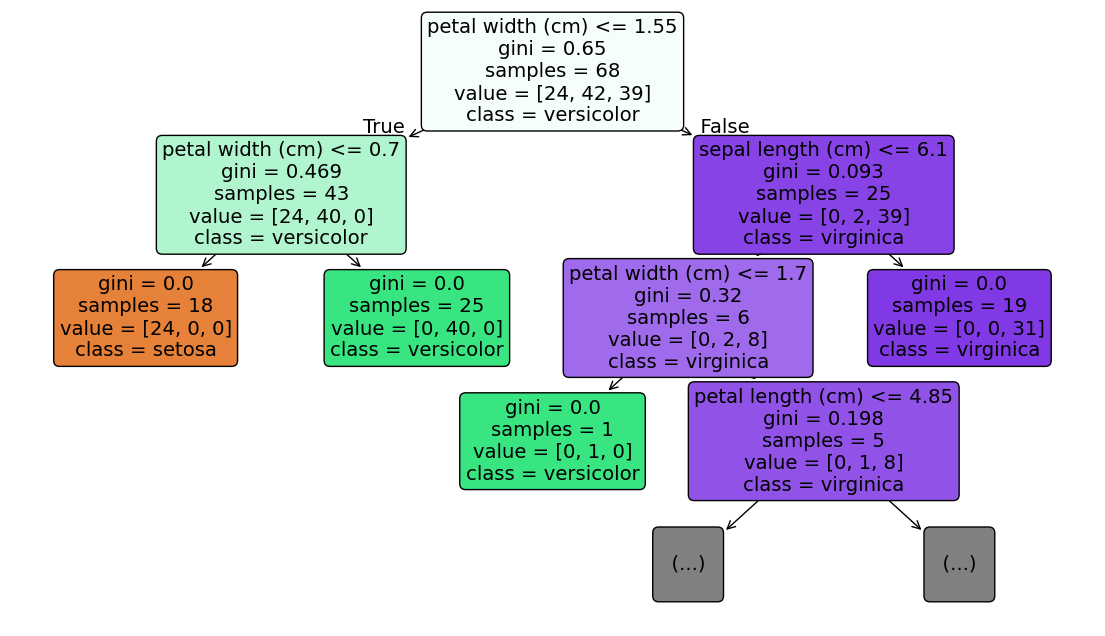

In [7]:
# رسم أول شجرة من الغابة
plt.figure(figsize=(14, 8))
plot_tree(rf.estimators_[0], feature_names=iris.feature_names,
          class_names=list(iris.target_names), filled=True, rounded=True, max_depth=3)
plt.show()

## 5) مقارنة أدق: Cross-validation

In [8]:
from sklearn.model_selection import cross_val_score

print("Decision Tree:", cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), X, y, cv=5).mean())
print("Random Forest:", cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X, y, cv=5).mean())

Decision Tree: 0.9733333333333334
Random Forest: 0.9666666666666668
